# 07. RT-DETR-L: learning rate 1e-4 (query-based, tuned)

Перший експеримент над `04`. Змінюємо одне: learning rate.

Чому: у `04` Ultralytics сам обрав AdamW з learning rate ≈ 8.3e-4 (режим `optimizer="auto"`). mAP на val досяг піку на 12-й епосі (0.236), а далі поступово падав до 0.19, хоча loss на train продовжував знижуватись. Це схоже на перенавчання і нестабільність через завеликий крок. Автори RT-DETR тренують з learning rate 1e-4, тобто у ~8 разів меншим. Тут ставимо AdamW з `lr0 = 1e-4`, решта як у `04`: ті самі кадри, `imgsz=640`, batch 8, 30 епох, та сама оцінка.

Що очікуємо: повільніший старт, але без падіння після піку і, можливо, вищий найкращий mAP.

Потрібно: GPU T4 і увімкнений Internet.

## 0. Налаштування

In [1]:
%pip install -q ultralytics==8.4.193 pycocotools

Note: you may need to restart the kernel to use updated packages.


In [2]:
import json
import os
import time
import warnings
from pathlib import Path

import numpy as np
import polars as pl
import matplotlib.pyplot as plt
import torch

os.environ["WANDB_MODE"] = "disabled"
os.environ["YOLO_VERBOSE"] = "False"

import ultralytics
from ultralytics import RTDETR
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

ultralytics.settings.update({"wandb": False, "raytune": False})
warnings.filterwarnings("ignore", message=".*does not have a deterministic implementation.*")

SEED = 42
CLASSES = ["person", "bicycle", "car", "van", "truck", "tricycle", "bus", "motor"]

MODEL = "rtdetr-l.pt"
RUN_NAME = "rtdetr_l_640_lr1e-4"
LR0 = 1e-4
IMGSZ = 640
BATCH = 8
EPOCHS = 30
STEP = 5

print("ultralytics", ultralytics.__version__, "| torch", torch.__version__, "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "немає")

ultralytics 8.4.193 | torch 2.11.0+cu128 | GPU: Tesla T4


Шукаємо дані так само, як в `01_eda`. Усі результати пишемо в `/kaggle/working`, звідти Kaggle зберігає їх після запуску.

In [3]:
ROOT = next(
    path.parent
    for pattern in ["*/test_images.csv", "*/*/test_images.csv", "*/*/*/test_images.csv"]
    for path in Path("/kaggle/input").glob(pattern)
)
OUT = Path("/kaggle/working")
print(ROOT)

/kaggle/input/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026


## 1. Дані для тренування

Ultralytics вміє брати список картинок з текстового файлу, а мітки сам шукає в сусідній папці `labels`. Тому нічого не копіюємо: робимо список кожного 5-го кадру train і список усіх кадрів val.

In [4]:
def frame_list(split):
    return pl.DataFrame({"path": sorted(str(path) for path in (ROOT / split / "images").rglob("*.jpg"))}).with_columns(
        video=pl.col("path").str.split("/").list.get(-2)
    )


train_frames = frame_list("train").filter((pl.int_range(pl.len()).over("video") % STEP) == 0)
val_frames = frame_list("val")

(OUT / "train_list.txt").write_text("\n".join(train_frames["path"]))
(OUT / "val_list.txt").write_text("\n".join(val_frames["path"]))

(OUT / "data.yaml").write_text(
    f"train: {OUT / 'train_list.txt'}\n"
    f"val: {OUT / 'val_list.txt'}\n"
    f"nc: {len(CLASSES)}\n"
    f"names: {json.dumps(CLASSES)}\n"
)

print("train:", train_frames.height, "кадрів з", train_frames["video"].n_unique(), "відео")
print("val:", val_frames.height, "кадрів з", val_frames["video"].n_unique(), "відео")

train: 4868 кадрів з 56 відео
val: 2846 кадрів з 7 відео


## 2. Тренування

Стартуємо з ваг RT-DETR-L, натренованих на COCO. Від `04` відрізняється лише learning rate: явно задаємо той самий AdamW з momentum 0.9, який в `04` обрав автоматичний режим, але з `lr0 = 1e-4` замість ≈ 8.3e-4. Попередження про недетермінований `grid_sampler` (у `04` воно друкувалось 30 разів) приглушуємо. Відомо, що DETR-моделі сходяться повільніше за CNN, тому за ті самі 30 епох модель може не встигнути навчитися до кінця. Це якраз те, що треба показати на графіку нижче. Після кожної епохи друкуємо один рядок з mAP, щоб у логах було видно, як іде тренування.

In [5]:
model = RTDETR(MODEL)
start = time.time()


def log_epoch(trainer):
    if trainer.epoch < trainer.epochs:
        print(f"епоха {trainer.epoch + 1}/{trainer.epochs} | {(time.time() - start) / 60:.0f} хв | mAP50-95 {trainer.metrics.get('metrics/mAP50-95(B)', float('nan')):.4f}", flush=True)


model.add_callback("on_fit_epoch_end", log_epoch)
model.train(
    data=str(OUT / "data.yaml"),
    imgsz=IMGSZ,
    batch=BATCH,
    epochs=EPOCHS,
    optimizer="AdamW",
    lr0=LR0,
    momentum=0.9,
    seed=SEED,
    deterministic=True,
    workers=4,
    device=0,
    project=str(OUT / "runs"),
    name=RUN_NAME,
    exist_ok=True,
    plots=True,
)
train_hours = (time.time() - start) / 3600
actual_batch, accumulate = model.trainer.batch_size, model.trainer.accumulate
print(f"тренування: {train_hours:.2f} год | batch {actual_batch}, accumulate {accumulate}")

епоха 1/30 | 8 хв | mAP50-95 0.0235
епоха 2/30 | 15 хв | mAP50-95 0.0342
епоха 3/30 | 22 хв | mAP50-95 0.0998
епоха 4/30 | 28 хв | mAP50-95 0.1599
епоха 5/30 | 35 хв | mAP50-95 0.1719
епоха 6/30 | 42 хв | mAP50-95 0.1808
епоха 7/30 | 48 хв | mAP50-95 0.1781
епоха 8/30 | 55 хв | mAP50-95 0.1959
епоха 9/30 | 61 хв | mAP50-95 0.1912
епоха 10/30 | 68 хв | mAP50-95 0.1880
епоха 11/30 | 75 хв | mAP50-95 0.1981
епоха 12/30 | 81 хв | mAP50-95 0.1954
епоха 13/30 | 88 хв | mAP50-95 0.1922
епоха 14/30 | 94 хв | mAP50-95 0.1996
епоха 15/30 | 101 хв | mAP50-95 0.1819
епоха 16/30 | 108 хв | mAP50-95 0.2081
епоха 17/30 | 114 хв | mAP50-95 0.1894
епоха 18/30 | 121 хв | mAP50-95 0.1976
епоха 19/30 | 128 хв | mAP50-95 0.2017
епоха 20/30 | 134 хв | mAP50-95 0.1932
епоха 21/30 | 141 хв | mAP50-95 0.2029
епоха 22/30 | 147 хв | mAP50-95 0.1970
епоха 23/30 | 153 хв | mAP50-95 0.1957
епоха 24/30 | 160 хв | mAP50-95 0.1923
епоха 25/30 | 166 хв | mAP50-95 0.1928
епоха 26/30 | 173 хв | mAP50-95 0.1943
епоха 27/3

Криві тренування. У RT-DETR інші лоси, ніж у YOLO: `giou_loss` і `l1_loss` для рамок, `cls_loss` для класу. Криву mAP потім покладемо поруч з кривою YOLO з `02`, як просить завдання.

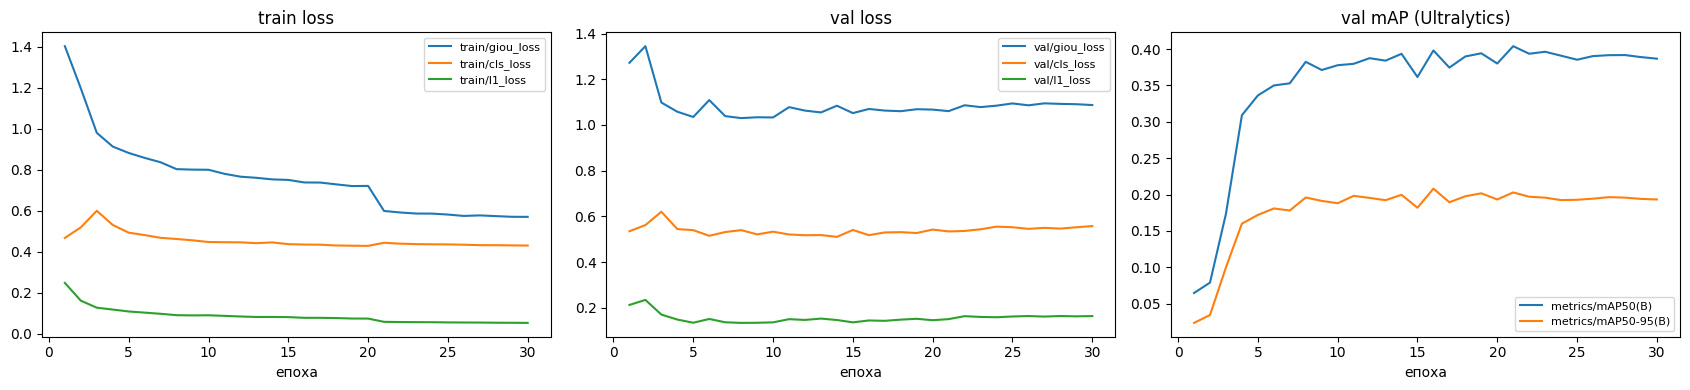

In [6]:
run_dir = OUT / "runs" / RUN_NAME
history = pl.read_csv(run_dir / "results.csv")
history = history.rename({name: name.strip() for name in history.columns})
train_losses = [name for name in history.columns if name.startswith("train/")]
val_losses = [name for name in history.columns if name.startswith("val/")]

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for name in train_losses:
    axes[0].plot(history["epoch"], history[name], label=name)
for name in val_losses:
    axes[1].plot(history["epoch"], history[name], label=name)
for name in ["metrics/mAP50(B)", "metrics/mAP50-95(B)"]:
    axes[2].plot(history["epoch"], history[name], label=name)
axes[0].set_title("train loss")
axes[1].set_title("val loss")
axes[2].set_title("val mAP (Ultralytics)")
for ax in axes:
    ax.set_xlabel("епоха")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 3. Оцінка на val за нашим протоколом

Метрики Ultralytics не враховують ignored regions і не рахують AP_small, тому робимо свою оцінку:
- передбачаємо всі кадри val з низьким порогом впевненості (0.001), бо mAP сам перебирає пороги;
- кадри подаємо порціями по 16: якщо передати весь список одразу, Ultralytics завантажує всі картинки в пам'ять, і на кадрах 4K закінчується RAM;
- `max_det=500`, як на Kaggle;
- переводимо рамки в COCO-формат і рахуємо `COCOeval` з оригінальним `annotations_coco.json` (там ignored regions уже позначені `iscrowd = 1`);
- у `COCOeval` ставимо ліміт 500 детекцій на кадр замість стандартних 100, бо в нас буває до 180 об'єктів на кадрі.

In [7]:
best = RTDETR(run_dir / "weights" / "best.pt")

val_coco = json.loads((ROOT / "val" / "annotations_coco.json").read_text())
image_ids = {"/".join(Path(image["file_name"]).parts[-2:]): image["id"] for image in val_coco["images"]}

val_paths = val_frames["path"].to_list()
detections = []
speeds = []
for chunk_start in range(0, len(val_paths), 16):
    for result in best.predict(source=val_paths[chunk_start:chunk_start + 16], batch=16, imgsz=IMGSZ, conf=0.001, max_det=500, verbose=False, device=0):
        speeds.append(sum(result.speed.values()))
        height, width = result.orig_shape
        boxes = result.boxes.xyxy.cpu().numpy().clip(0, [width, height, width, height])
        detections += [
            {"image_id": image_ids["/".join(Path(result.path).parts[-2:])], "category_id": int(cls) + 1, "bbox": [round(float(x1), 2), round(float(y1), 2), round(float(x2 - x1), 2), round(float(y2 - y1), 2)], "score": round(float(score), 4)}
            for (x1, y1, x2, y2), cls, score in zip(boxes, result.boxes.cls.cpu().numpy(), result.boxes.conf.cpu().numpy())
        ]

(OUT / f"val_predictions_{RUN_NAME}.json").write_text(json.dumps(detections))
ms_per_image = float(np.mean(speeds))
print(len(detections), "детекцій на", len(image_ids), "кадрах;", f"{ms_per_image:.1f} ms/кадр")

853800 детекцій на 2846 кадрах; 42.8 ms/кадр


In [8]:
ground_truth = COCO(str(ROOT / "val" / "annotations_coco.json"))
evaluator = COCOeval(ground_truth, ground_truth.loadRes(str(OUT / f"val_predictions_{RUN_NAME}.json")), "bbox")
evaluator.params.maxDets = [1, 100, 500]
evaluator.evaluate()
evaluator.accumulate()
evaluator.summarize()

loading annotations into memory...
Done (t=0.46s)
creating index...
index created!
Loading and preparing results...
DONE (t=5.42s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=227.89s).
Accumulating evaluation results...
DONE (t=12.51s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.212
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=500 ] = 0.405
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=500 ] = 0.194
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=500 ] = 0.089
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=500 ] = 0.177
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=500 ] = 0.381
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.118
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.359
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxD

Зводимо головні цифри в один рядок і зберігаємо в файл. Головний mAP рахуємо сам з таблиці precision при ліміті 500 детекцій: `summarize()` у `pycocotools` перший рядок завжди рахує з лімітом 100, навіть якщо змінити `maxDets`.

In [9]:
stats = evaluator.stats
precision_500 = evaluator.eval["precision"][:, :, :, 0, -1]
result_row = {
    "run": RUN_NAME,
    "model": MODEL,
    "imgsz": IMGSZ,
    "lr0": LR0,
    "batch": actual_batch,
    "accumulate": accumulate,
    "epochs": EPOCHS,
    "train_frames": train_frames.height,
    "mAP": round(float(np.mean(precision_500[precision_500 > -1])), 4),
    "mAP_maxdet100": round(stats[0], 4),
    "AP50": round(stats[1], 4),
    "AP75": round(stats[2], 4),
    "AP_small": round(stats[3], 4),
    "AP_medium": round(stats[4], 4),
    "AP_large": round(stats[5], 4),
    "AR500": round(stats[8], 4),
    "ms_per_image": round(ms_per_image, 1),
    "train_hours": round(train_hours, 2),
}
(OUT / f"result_{RUN_NAME}.json").write_text(json.dumps(result_row, indent=2))
pl.DataFrame([result_row])

run,model,imgsz,lr0,batch,accumulate,epochs,train_frames,mAP,mAP_maxdet100,AP50,AP75,AP_small,AP_medium,AP_large,AR500,ms_per_image,train_hours
str,str,i64,f64,i64,i64,i64,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""rtdetr_l_640_lr1e-4""","""rtdetr-l.pt""",640,0.0001,8,8,30,4868,0.2123,0.2118,0.4046,0.1938,0.0889,0.1766,0.3811,0.3634,42.8,3.34


AP по кожному класу окремо: середній mAP може ховати класи, які модель майже не знаходить.

In [10]:
precision = evaluator.eval["precision"][:, :, :, 0, -1]
pl.DataFrame(
    [
        {
            "class": name,
            "AP": round(float(np.mean(precision[:, :, i][precision[:, :, i] > -1])), 4) if (precision[:, :, i] > -1).any() else None,
            "AP50": round(float(np.mean(precision[0, :, i][precision[0, :, i] > -1])), 4) if (precision[0, :, i] > -1).any() else None,
        }
        for i, name in enumerate(CLASSES)
    ]
)

class,AP,AP50
str,f64,f64
"""person""",0.2529,0.6152
"""bicycle""",0.1018,0.2385
"""car""",0.3958,0.6265
"""van""",0.23,0.3746
"""truck""",0.2551,0.4409
"""tricycle""",0.1964,0.4214
"""bus""",0.1557,0.1924
"""motor""",0.1112,0.3276


## 4. Сабміт на Kaggle

Передбачаємо всі кадри test з тими самими налаштуваннями. На відміну від YOLO, RT-DETR не обрізає рамки по краях кадру, тому обрізаємо їх самі (так само і для val вище). Формат рядка: `class score x y width height`, де (x, y) — лівий верхній кут у пікселях оригінального кадру. Ultralytics повертає рамки вже в пікселях оригіналу, тож лишається перевести кути в ширину і висоту. Кадри без детекцій лишаються з порожнім рядком.

In [11]:
test_images = pl.read_csv(ROOT / "test_images.csv")
test_ids = {"/".join(Path(file_name).parts[-2:]): image_id for image_id, file_name in test_images.select("image_id", "file_name").iter_rows()}

test_paths = [str(ROOT / file_name) for file_name in test_images["file_name"]]
predictions = {}
for chunk_start in range(0, len(test_paths), 16):
    for result in best.predict(source=test_paths[chunk_start:chunk_start + 16], batch=16, imgsz=IMGSZ, conf=0.001, max_det=500, verbose=False, device=0):
        height, width = result.orig_shape
        boxes = result.boxes.xyxy.cpu().numpy().clip(0, [width, height, width, height])
        predictions[test_ids["/".join(Path(result.path).parts[-2:])]] = " ".join(
            f"{int(cls)} {score:.4f} {x1:.1f} {y1:.1f} {x2 - x1:.1f} {y2 - y1:.1f}"
            for (x1, y1, x2, y2), cls, score in zip(boxes, result.boxes.cls.cpu().numpy(), result.boxes.conf.cpu().numpy())
        )

submission = test_images.select("image_id").with_columns(
    PredictionString=pl.col("image_id").replace_strict(predictions, default="")
)
submission.write_csv(OUT / "submission.csv")
submission.write_csv(OUT / f"submission_{RUN_NAME}.csv")
print(submission.height, "рядків,", (submission["PredictionString"] == "").sum(), "порожніх")
submission.head()

3811 рядків, 0 порожніх


image_id,PredictionString
str,str
"""clip_001_0000001""","""0 0.8488 629.9 915.5 61.3 163.…"
"""clip_001_0000002""","""0 0.8489 623.8 923.2 64.5 156.…"
"""clip_001_0000003""","""0 0.8327 614.1 933.1 69.2 146.…"
"""clip_001_0000004""","""0 0.8346 703.6 905.6 63.1 172.…"
"""clip_001_0000005""","""0 0.8334 727.5 914.8 70.6 163.…"


Перевірка формату перед відправкою: кількість рядків як у `test_images.csv`, у кожній групі 6 чисел, класи від 0 до 7, рамки не виходять за межі кадру.

In [12]:
rows = (
    submission.join(test_images.select("image_id", "width", "height"), on="image_id")
    .filter(pl.col("PredictionString") != "")
    .with_columns(values=pl.col("PredictionString").str.split(" ").cast(pl.List(pl.Float64)))
)
boxes = rows.select(
    "width",
    "height",
    *[pl.col("values").list.gather_every(6, offset).alias(name) for offset, name in enumerate(["cls", "score", "x", "y", "w", "h"])],
).explode("cls", "score", "x", "y", "w", "h")

{
    "рядків як у test_images.csv": submission.height == test_images.height,
    "кількість чисел кратна 6": rows.select((pl.col("values").list.len() % 6 == 0).all()).item(),
    "не більше 500 рамок на кадр": rows.select((pl.col("values").list.len() <= 6 * 500).all()).item(),
    "класи від 0 до 7": boxes["cls"].is_between(0, 7).all(),
    "score від 0 до 1": boxes["score"].is_between(0, 1).all(),
    "рамки в межах кадру": boxes.select(
        ((pl.col("x") >= -1) & (pl.col("y") >= -1) & (pl.col("x") + pl.col("w") <= pl.col("width") + 1) & (pl.col("y") + pl.col("h") <= pl.col("height") + 1)).all()
    ).item(),
}

{'рядків як у test_images.csv': True,
 'кількість чисел кратна 6': True,
 'не більше 500 рамок на кадр': True,
 'класи від 0 до 7': True,
 'score від 0 до 1': True,
 'рамки в межах кадру': True}